# Complex Project

## Phase 2 Update

So far we have explored the dataset and finished the text mining basics: message length, distinctive words, word clouds, text signals, and sentiment by label. Scam messages stand out clearly from ham because they are longer, contain more digits and phone numbers, include a call to action, and sound more positive. Next we will combine spam and smishing into one "scam" class and build a classifier using these features in Phase 3.

In [1]:
# import data

import pandas as pd
import matplotlib.pyplot as plt
import re
import string
import numpy as np
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from wordcloud import WordCloud


In [2]:
def load_data(path):
    df = pd.read_csv(path)
    df["LABEL"] = df["LABEL"].str.strip().str.lower()
    df["TEXT"] = df["TEXT"].str.strip()
    for c in ["URL", "EMAIL", "PHONE"]:
        df[c] = df[c].str.lower().eq("yes")
    return df

df = load_data("../Dataset_5971.csv")

Rows, columns: (5971, 5)

Missing values:
 LABEL    0
TEXT     0
URL      0
EMAIL    0
PHONE    0
dtype: int64

Duplicate rows: 95
          count   pct
LABEL                
ham        4844  81.1
smishing    638  10.7
spam        489   8.2


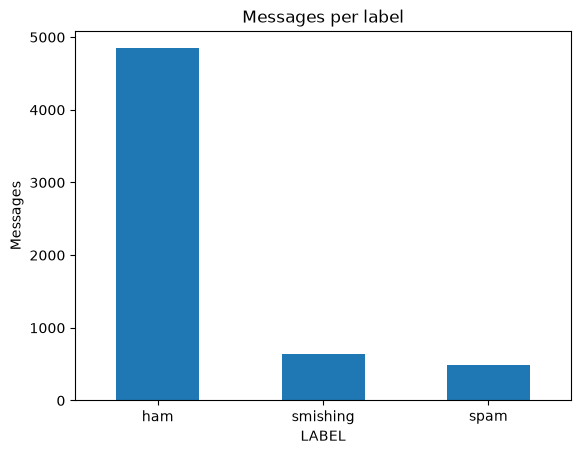

In [3]:
# basic stats

def basic_stats(df):
    print("Rows, columns:", df.shape)
    print("\nMissing values:\n", df.isna().sum())
    print("\nDuplicate rows:", df.duplicated().sum())
    counts = df["LABEL"].value_counts()
    print(pd.DataFrame({"count": counts, "pct": (counts / len(df) * 100).round(1)}))
    counts.plot(kind="bar", title="Messages per label", rot=0)
    plt.ylabel("Messages")
    plt.show()

basic_stats(df)
df = df.drop_duplicates().reset_index(drop=True)

The raw data has 5,971 messages with no missing values. We removed 95 exact duplicate rows (71 of them smishing), leaving 5,876. The classes are imbalanced: about 82% ham, 10% smishing, and 8% spam. A model that labeled everything “ham” would be 82% accurate but useless, so in Phase 3 we will judge models by per-class precision.

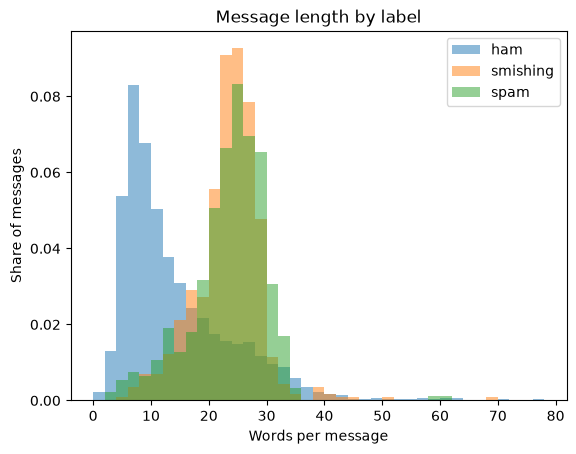

,count,mean,std,min,25%,50%,75%,max
LABEL,,,,,,,,
ham,4834.0,70.7,56.2,2.0,34.0,53.0,91.0,910.0
smishing,567.0,140.3,32.5,33.0,128.0,146.0,156.0,383.0
spam,475.0,133.6,34.2,18.0,118.0,142.0,155.0,379.0


,count,mean,std,min,25%,50%,75%,max
LABEL,,,,,,,,
ham,4834.0,14.2,11.1,1.0,7.0,11.0,19.0,171.0
smishing,567.0,22.9,5.9,5.0,20.0,23.0,26.5,68.0
spam,475.0,23.0,6.6,2.0,20.0,24.0,27.0,61.0


In [4]:
# text length distribution

def add_length(df):
    df["chars"] = df["TEXT"].str.len()
    df["words"] = df["TEXT"].str.split().str.len()
    return df

def plot_length(df):
    for label, g in df.groupby("LABEL"):
        plt.hist(g["words"], bins=range(0, 80, 2), alpha=0.5, density=True, label=label)
    plt.xlabel("Words per message")
    plt.ylabel("Share of messages")
    plt.title("Message length by label")
    plt.legend()
    plt.show()
    display(df.groupby("LABEL")["chars"].describe().round(1))
    display(df.groupby("LABEL")["words"].describe().round(1))

df = add_length(df)
plot_length(df)

Text length distribution shows a clear divide between ham and smishing/spam in word length. This is a good sign and a promising way to indicate if a message is ham or not, as real messages are often shorter.

In [5]:
# sample examples

samples = df.groupby("LABEL").sample(3, random_state=42)[["LABEL", "TEXT"]]
samples.style.set_properties(**{"text-align": "left", "white-space": "normal"}).set_table_styles(
    [{"selector": "th", "props": [("text-align", "left")]}])

,LABEL,TEXT
5246,ham,"We know TAJ MAHAL as symbol of love. But the other lesser known facts 1. Mumtaz was Shahjahan's 4th wife, out of his 7 wifes. 2. Shahjahan killed Mumtaz's husband to marry her. 3. Mumtaz died in her <#> th delivery. 4. He then married Mumtaz's sister. Question arises where the Hell is the LOVE?:-| -The Great Hari-"
2061,ham,Baaaaabe! I misss youuuuu ! Where are you ? I have to go and teach my class at 5 ...
1279,ham,That means from february to april i'll be getting a place to stay down there so i don't have to hustle back and forth during audition season as i have since my sister moved away from harlem.
3876,smishing,Your free gift is waiting to be collected. Simply call 08718738034
3831,smishing,WE WILL HOLD YOUR PAYTM AMOUNT AFTER SOMETIME COMPLETE YOUR PAYTM KYC PAYTM OFFICE PH 7679046492
4031,smishing,XMAS REWARD IS WAITING FOR YOU! Our computer has randomly picked you from our mobile customers to receive a $ 400 reward. Just call 09066364589
1889,spam,Can U get 2 phone NOW? I wanna chat 2 set up meet Call me NOW on 09096102316 U can cum here 2moro Luv JANE xx Calls£1/minmoremobsEMSPOBox45PO139WA
4737,spam,No 1 POLYPHONIC tone 4 ur mob every week! Just txt PT2 to 87575. so get txtin now and tell ur friends. 16 reply HL 4info
2128,spam,Valentines Day Special! Win over £1000 in our quiz and take your partner on the trip of a lifetime! Send GO to 83600 now. 150p/msg rcvd. CustCare:08718720201.


# Text Mining Basics

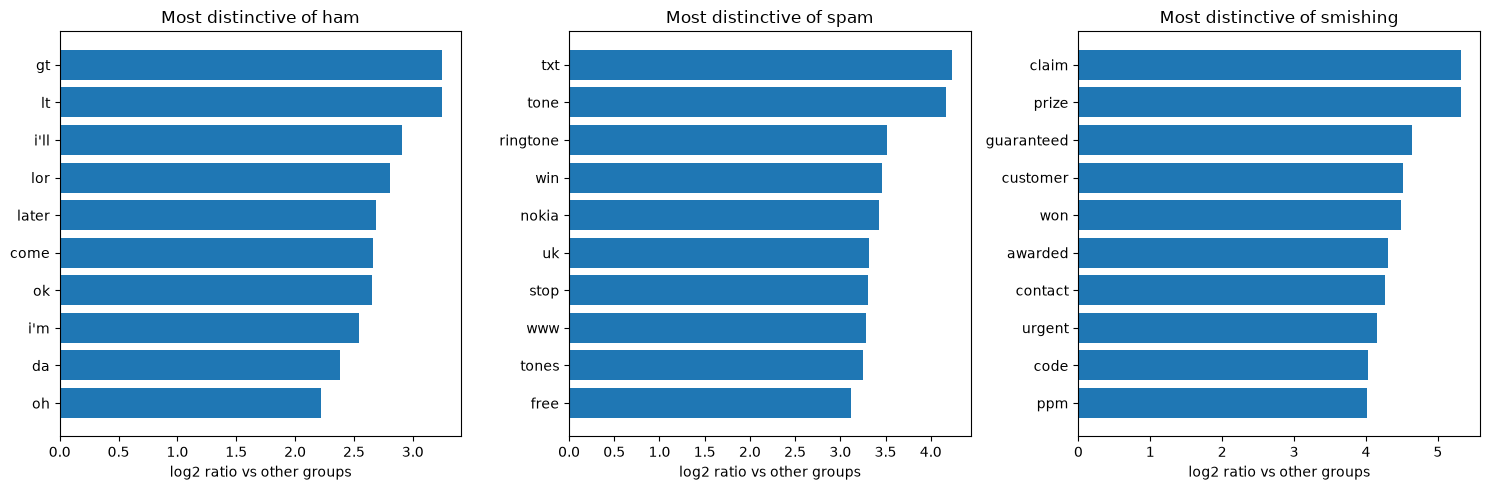

,word,% ham,% others,log_ratio
151,gt,4.26,0.00,3.25
154,lt,4.26,0.00,3.25
131,i'll,3.27,0.00,2.91
39,lor,3.00,0.00,2.81
286,later,2.73,0.00,2.69
6,come,4.49,0.29,2.66
37,ok,5.67,0.48,2.65
64,i'm,7.45,0.86,2.54
49,da,2.61,0.10,2.38
87,oh,2.28,0.10,2.22


,word,% spam,% others,log_ratio
38,txt,25.26,0.87,4.23
17,tone,8.84,0.02,4.17
89,ringtone,6.11,0.07,3.52
65,win,10.95,0.54,3.46
63,nokia,9.05,0.39,3.43
12,uk,10.95,0.65,3.32
0,stop,16.63,1.22,3.31
6,www,14.74,1.07,3.28
18,tones,4.42,0.02,3.25
8,free,26.74,2.63,3.12


,word,% smishing,% others,log_ratio
19,claim,26.28,0.17,5.32
13,prize,21.69,0.06,5.32
38,guaranteed,13.40,0.06,4.64
12,customer,20.28,0.41,4.51
10,won,13.23,0.11,4.49
6,awarded,9.35,0.00,4.30
50,contact,16.40,0.38,4.27
33,urgent,14.46,0.34,4.16
20,code,8.29,0.04,4.03
103,ppm,7.94,0.02,4.02


In [ ]:
# separate data

def tokenize(text):
    words = re.findall(r"[a-z']+", text.lower())
    return [w for w in words if w not in ENGLISH_STOP_WORDS and len(w) > 1]

def distinctive_words(df, label, n=10, min_count=10):
    is_a = df["LABEL"] == label
    ca = Counter(w for t in df.loc[is_a, "TEXT"] for w in set(tokenize(t)))
    cb = Counter(w for t in df.loc[~is_a, "TEXT"] for w in set(tokenize(t)))
    rows = [(w, ca[w] / is_a.sum() * 100, cb[w] / (~is_a).sum() * 100) for w in ca if ca[w] >= min_count]
    out = pd.DataFrame(rows, columns=["word", f"% {label}", "% others"])
    out["log_ratio"] = np.log2((out[f"% {label}"] + 0.5) / (out["% others"] + 0.5))
    return out.sort_values("log_ratio", ascending=False).head(n).round(2)

labels = ["ham", "spam", "smishing"]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, label in zip(axes, labels):
    d = distinctive_words(df, label)
    ax.barh(d["word"][::-1], d["log_ratio"][::-1])
    ax.set_title(f"Most distinctive of {label}")
    ax.set_xlabel("log2 ratio vs other groups")
plt.tight_layout()
plt.show()

for label in labels:
    display(distinctive_words(df, label))

Each group has a pretty distinctive tone to it. Ham is casual, using words like "oh" and "later" plus some slang like "da" and "lor." Spam uses a lot of marketing and action words, like "txt," "free," and "win." Smishing also uses marketing and action words, leaning on the urgent side like "claim," "prize," "urgent," and "awarded." Smishing and spam are decently similar, but ham is distinctive. Comparing incoming messages against these frequent words should be a good indicator to classify them.

In [7]:
#compare data sets

def text_signals(df):
    t = df["TEXT"]
    out = pd.DataFrame({
        "LABEL": df["LABEL"],
        "punctuation": t.str.count(f"[{re.escape(string.punctuation)}]"),
        "exclaim": t.str.count("!"),
        "question": t.str.count(r"\?"),
        "two_dots": t.str.count(r"(?<!\.)\.\.(?!\.)"),
        "has_two_dots": t.str.contains(r"(?<!\.)\.\.(?!\.)"),
        "three_plus_dots": t.str.count(r"\.{3,}"),
        "has_three_plus_dots": t.str.contains(r"\.{3,}"),
        "emoticon": t.str.contains(r"[:;]-?[)(DPp]"),
        "has_@": t.str.contains("@"),
        "has_#": t.str.contains("#"),
        "has_url": t.str.contains(r"http|www\.|\.com|\.co\.uk|\.ly|\.io", case=False),
        "has_currency": t.str.contains(r"[£$€]"),
        "digits": t.str.count(r"\d"),
        "numbers": t.str.count(r"\d+"),
        "has_number": t.str.contains(r"\d"),
        "has_phone": t.str.contains(r"\d{10,}"),
        "has_shortcode": t.str.contains(r"\b\d{4,6}\b"),
        "caps_pct": t.str.count(r"[A-Z]") / t.str.len() * 100,
        "caps_words": t.str.count(r"\b[A-Z]{2,}\b"),
        "call_to_action": t.str.contains(r"\b(?:call|txt|text|reply|click|send|visit)\b", case=False),
    })
    return out.groupby("LABEL").mean().round(2).T

text_signals(df)

LABEL,ham,smishing,spam
punctuation,3.82,5.64,6.08
exclaim,0.18,0.64,0.55
question,0.29,0.14,0.27
two_dots,0.15,0.01,0.03
has_two_dots,0.10,0.01,0.02
three_plus_dots,0.24,0.01,0.01
has_three_plus_dots,0.15,0.01,0.01
emoticon,0.07,0.01,0.00
has_@,0.00,0.03,0.07
has_#,0.04,0.01,0.00


Smishing and spam look very similar on these text signals, while ham stands apart. About 77% of scam messages include a call to action (call, txt, reply, click) compared to 9% of ham. Scams average 12 to 17 digits per message versus 0.3 for ham, and 74% of smishing messages contain a phone number while ham almost never does. Scams also use about twice as many capital letters and more exclamation points, while ham is more likely to use casual punctuation like "..." and emoticons. These signals should make strong features for the Phase 3 classifier.

In [8]:
#sentiment analysis

sia = SentimentIntensityAnalyzer()

def add_sentiment(df):
    df["sentiment"] = df["TEXT"].apply(lambda t: sia.polarity_scores(t)["compound"])
    df["sent_class"] = pd.cut(df["sentiment"], [-1.01, -0.05, 0.05, 1], labels=["negative", "neutral", "positive"])
    return df

def sentiment_table(df):
    shares = pd.crosstab(df["LABEL"], df["sent_class"], normalize="index").mul(100).round(1).add_prefix("% ")
    scores = df.groupby("LABEL")["sentiment"].agg(mean="mean", median="median").round(2)
    return scores.join(shares)

df = add_sentiment(df)
sentiment_table(df)

,mean,median,% negative,% neutral,% positive
LABEL,,,,,
ham,0.17,0.00,18.1,37.5,44.4
smishing,0.53,0.70,8.3,11.1,80.6
spam,0.35,0.44,15.6,17.7,66.7


Smishing is the most positive class, followed by spam, with ham the least positive. Scams likely sound upbeat because they promise prizes and rewards. For our model, a positive tone in a message is an indicator of possible scam. Sentiment may be a helpful extra feature.

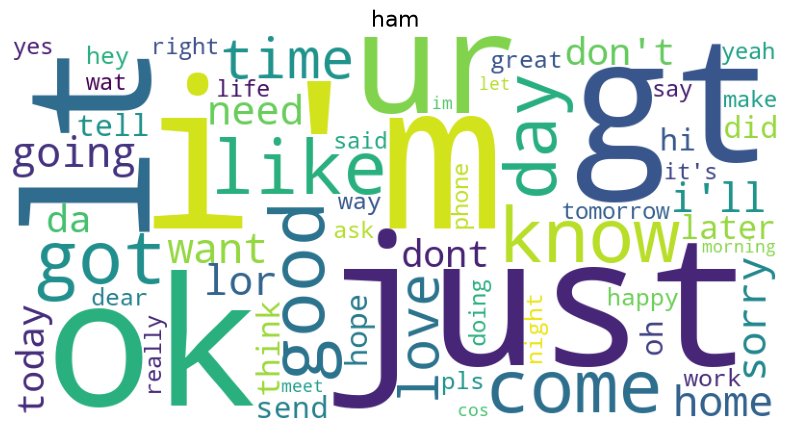

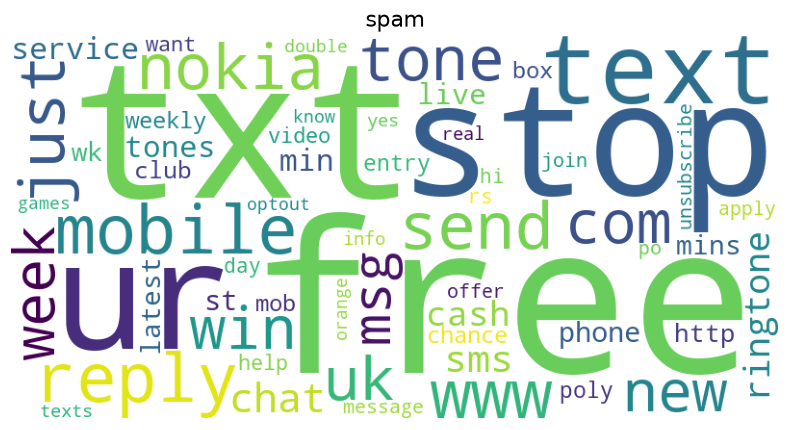

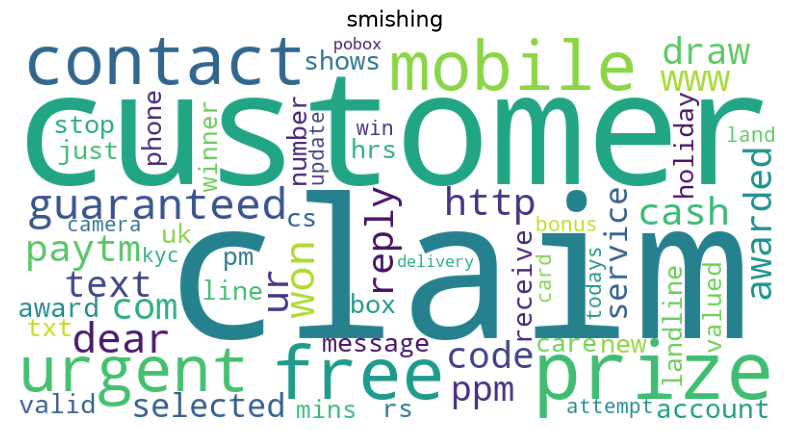

In [9]:
#wordclouds

def plot_wordclouds(df):
    for label in ["ham", "spam", "smishing"]:
        freqs = Counter(w for t in df.loc[df["LABEL"] == label, "TEXT"] for w in tokenize(t))
        wc = WordCloud(width=800, height=400, background_color="white", max_words=60).generate_from_frequencies(freqs)
        plt.figure(figsize=(10, 5))
        plt.imshow(wc)
        plt.title(label, fontsize=16)
        plt.axis("off")
        plt.show()

plot_wordclouds(df)

The word clouds show the most common words in each group and support the distinctive word charts. Ham is everyday conversation ("know," "good," "come," "love," "sorry"). Spam and smishing both rely on "free," "txt," and "reply," but they want different things. Spam is mostly advertising subscriptions and ringtones ("stop," "tones," "nokia," "unsubscribe"). Smishing pressures the reader to act on a fake prize or account ("claim," "prize," "urgent," "customer," "account," "code"). Since both are unwanted and share most of their vocabulary, combining them into one "scam" class for Phase 3 makes sense.

## Plan for Phase 3

This project will follow path A, the classification model. We will build a model where a user can input a message they've received, and the model will return a guess if it is a scam or not. We noticed large similarities between the smishing and spam categories, in comparison to the ham category, so our classifier will combine these two categories into a "scam" category and tell you if the message is safe or not.

To build this model, we will categorize ham in the following ways:
- Short messages (median 11 words, vs. about 23 for scams)
- Casual, conversational words and slang (“later,” “sorry,” “got,” “lor”)
- No reward or urgency words (“claim,” “prize,” “urgent,” “free,” “win”)
- Very few digits, and almost never a phone number or short code
- No currency symbols or URLs
- Fewer capital letters and all-caps words
- Casual punctuation like “...” and emoticons such as “:)”
- Rarely asks the reader to call, text, reply or click (9% vs. about 75% of scams)
- Neutral or mildly positive tone, not overly upbeat

We do not plan to use the Claude API, since the features above can be computed directly from the text and a standard classifier should handle this well. Claude may help us write code or generate sample texts to test the model. Topic modeling was also not needed, since the dataset is already labeled and our goal is classification.

We have a few concerns with this approach:
- **Class imbalance:** about 82% of messages are ham. Even after combining spam and smishing, scams make up only about 18% of the data. We will use a stratified train/test split and judge the model by precision and recall on the scam class instead of overall accuracy.
- **Outdated data:** words like "nokia," "ringtone," and "paytm" suggest many messages are older and come from the UK and India. Newer scams, such as fake package delivery, toll, or bank alerts, may look different, so the model could miss them.
- **Privacy:** real texts often contain names, phone numbers, and personal details, so any messages users enter should not be stored.
- **Test text validity:** sample texts generated by Claude may not be realistic, so we will not rely on them to judge model performance.